# 05 Model comparison

Compares the baselines with tuned learned models using the same grouped 5-fold cross-validation, metrics and training participants as notebook 03.

**Input:** `data/processed/harth_windows.csv` (from `02_preprocessing.ipynb`)
**Output:** tuning results, results table (macro F1 and balanced accuracy, mean ± SD across folds, training and prediction time) and confusion matrices. The test participants are not used.

**Sections**
1. Setup: data, training participants and folds (same as notebook 03)
2. Baselines: dummy and logistic regression
3. kNN
4. Decision tree
5. Random forest
6. Gradient boosting (TBC)
7. Results table and comparison (TBC)

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline 
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score 
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

In [2]:
print(Path.cwd())
# Create data directory 
data_directory = Path("../data/processed")
print(list(data_directory.iterdir()))

C:\Users\sarab\Projects\CT4101 ML Project\Machine_Learning_Portfolio_Project\notebooks
[WindowsPath('../data/processed/harth_windows.csv')]


In [3]:
# Read harth_windows csv file
harth_windows = pd.read_csv(data_directory/"harth_windows.csv")
harth_windows.head()

,back_x_mean,back_y_mean,back_z_mean,thigh_x_mean,thigh_y_mean,thigh_z_mean,back_mag_mean,thigh_mag_mean,back_x_sd,back_y_sd,...,back_x_range,back_y_range,back_z_range,thigh_x_range,thigh_y_range,thigh_z_range,back_mag_range,thigh_mag_range,activity,subject
0,-0.985535,0.076321,0.071897,-0.951721,0.066909,-0.300923,0.991294,1.000641,0.008179,0.015925,...,0.042021,0.106730,0.049085,0.026857,0.087156,0.065944,0.049257,0.030911,walking,S006
1,-0.990118,0.098939,0.052922,-0.970774,0.017955,-0.240916,0.996594,1.000600,0.006710,0.014250,...,0.021219,0.064559,0.039445,0.023676,0.082334,0.048104,0.021273,0.019548,standing,S006
2,-0.985489,0.114645,0.066351,-0.971958,0.013050,-0.227268,0.994405,0.998316,0.003794,0.007793,...,0.019534,0.039422,0.033895,0.007465,0.040694,0.031032,0.019653,0.008874,standing,S006
3,-0.986061,0.112886,0.061172,-0.971738,0.010761,-0.241171,0.994513,1.001399,0.004785,0.013871,...,0.021073,0.048442,0.034815,0.035844,0.036097,0.062481,0.023155,0.031511,standing,S006
4,-0.982235,0.143961,0.078188,-0.981988,0.051999,-0.167089,0.996508,1.000266,0.007308,0.028004,...,0.034060,0.127701,0.091557,0.051724,0.117495,0.212539,0.030263,0.033056,standing,S006


In [4]:
# Create a DataFrame with training data
TRAINING = ["S006", "S008", "S009", "S010", "S012", "S013", "S014", "S015", "S016", "S017", "S020", "S021", "S023", "S024", "S026", "S027", "S028", "S029"]

harth_windows_training = harth_windows[harth_windows["subject"].isin(TRAINING)]
harth_windows_training.shape

(96078, 26)

In [5]:
# Separate the inputs, target and groups
X = harth_windows_training.drop(columns=["activity", "subject"]) # inputs (24 features)
y = harth_windows_training["activity"] # target (activity column)
groups = harth_windows_training["subject"] # groups (who each row belongs to)

In [6]:
# 5 fold cross-validation with Stratified Group KFold
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

Baseline models from previous notebook for comparison later

In [7]:
# Dummy baseline to always predict the most common class (sitting)
model_dummy = DummyClassifier(strategy="most_frequent")
# Evaluate the dummy model with grouped 5-fold cross-validation
results_dummy = cross_validate(model_dummy, X, y, groups=groups, cv=cv, 
                               scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"})

In [45]:
# Create Logistic regression baseline
model_logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
# Evaluate the logreg model with grouped 5-fold cross-validation
results_logreg = cross_validate(model_logreg, X, y, groups=groups, cv=cv, 
                                scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"})
# Cross-validated predictions, each window is predicted by the model trained without its fold
pred_logreg = cross_val_predict(model_logreg, X, y, groups=groups, cv=cv)

#### kNN model

In [9]:
# Create kNN model 
model_knn = make_pipeline(StandardScaler(), 
                          KNeighborsClassifier())
# Try settings: number of neighbours, weights, and the distance measure
# (p=1 Manhattan, p=2 Euclidean)
param_grid_knn = {
"kneighborsclassifier__n_neighbors": [5, 15, 25, 45, 65],
"kneighborsclassifier__weights": ["uniform", "distance"],
"kneighborsclassifier__p": [1, 2],  
}

# Tune with same grouped 5-fold cross-validation as baselines.
# Use f1 to choose best settings
grid_knn = GridSearchCV(model_knn, param_grid_knn, cv=cv, 
                      scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"},
                       refit="f1")

grid_knn.fit(X, y, groups=groups)

# Best settings and mean macro F1 across the 5 folds
print(grid_knn.best_params_)
print(grid_knn.best_score_)

{'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__p': 1, 'kneighborsclassifier__weights': 'uniform'}
0.8082069518646335


In [10]:
# Scores for every combination tried
knn_results = pd.DataFrame(grid_knn.cv_results_)
knn_results[["param_kneighborsclassifier__n_neighbors", "param_kneighborsclassifier__weights", 
             "param_kneighborsclassifier__p", "mean_test_f1", "std_test_f1", "mean_test_balanced_accuracy"]]


,param_kneighborsclassifier__n_neighbors,param_kneighborsclassifier__weights,param_kneighborsclassifier__p,mean_test_f1,std_test_f1,mean_test_balanced_accuracy
0,5,uniform,1,0.805573,0.029447,0.803046
1,5,distance,1,0.802864,0.031583,0.797202
2,5,uniform,2,0.792069,0.054922,0.792447
3,5,distance,2,0.789821,0.056047,0.787775
4,15,uniform,1,0.808207,0.029984,0.798794
5,15,distance,1,0.807105,0.030987,0.796284
6,15,uniform,2,0.789574,0.054423,0.782638
7,15,distance,2,0.788591,0.054428,0.780440
8,25,uniform,1,0.805220,0.028926,0.793935
9,25,distance,1,0.804979,0.029704,0.792847


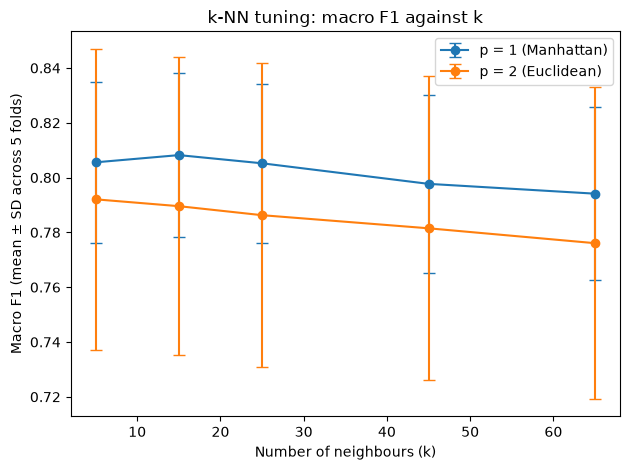

In [11]:
knn_uniform = knn_results[knn_results["param_kneighborsclassifier__weights"] == "uniform"]

for p, label in [(1, "p = 1 (Manhattan)"), (2, "p = 2 (Euclidean)")]:
    rows = knn_uniform[knn_uniform["param_kneighborsclassifier__p"] == p]
    plt.errorbar(rows["param_kneighborsclassifier__n_neighbors"], rows["mean_test_f1"],
                 yerr = rows["std_test_f1"], marker="o", capsize=4, label = label)
    
plt.xlabel("Number of neighbours (k)")
plt.ylabel("Macro F1 (mean ± SD across 5 folds)")
plt.title("kNN tuning: macro F1 against k")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# Best kNN model (k=15, uniform weights, Manhattan distance)
best_knn = grid_knn.best_estimator_

# Evaluate the tuned model with the same folds and metrics as other models
results_best_knn = cross_validate(best_knn, X, y, groups=groups, cv=cv,
                                  scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"})
pred_best_knn = cross_val_predict(best_knn, X, y, groups=groups, cv=cv)

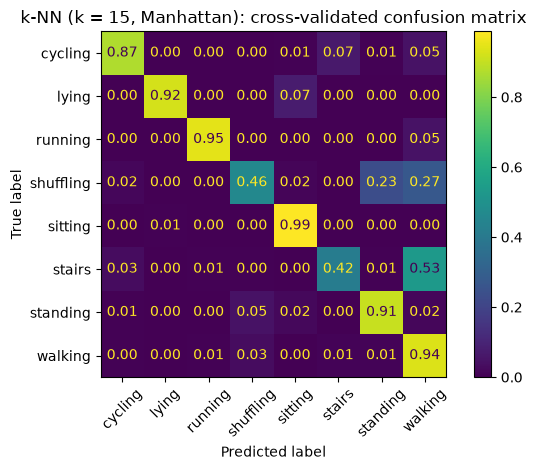

In [13]:
# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(y, pred_best_knn, normalize="true", values_format=".2f", xticks_rotation=45)
plt.title("kNN: cross-validated confusion matrix")
plt.tight_layout()
plt.show()

In [14]:
# Model results function: Mean and standard deviation of each metric across the 5 folds
# plus mean training and prediction time per fold (in seconds)
def results_dict(name, results):
    mean_f1 = results["test_f1"].mean()
    sd_f1 = results["test_f1"].std()
    mean_balancedaccuracy = results["test_balanced_accuracy"].mean()
    sd_balancedaccuracy = results["test_balanced_accuracy"].std()
    mean_trainingtime = results["fit_time"].mean()
    mean_predictiontime = results["score_time"].mean()

    summary = { "Model": name,
                "Macro F1": f"{mean_f1:.3f} ± {sd_f1:.3f}",
                "Balanced Accuracy": f"{mean_balancedaccuracy:.3f} ± {sd_balancedaccuracy:.3f}",
                "Training Time (s)": f"{mean_trainingtime:.2f}",
                "Prediction Time (s)": f"{mean_predictiontime:.2f}"}
    return(summary)

In [15]:
results_dummy_dict = results_dict("Dummy (most frequent)", results_dummy)
results_logreg_dict = results_dict("Logistic Regression", results_logreg)
results_knn_dict = results_dict("kNN", results_best_knn) 

# Combine all models into one results table (mean ± SD across folds)
# One row per model
results_table = [results_dummy_dict, 
                 results_logreg_dict, 
                 results_knn_dict]
results_table = pd.DataFrame(results_table).set_index("Model")
results_table

,Macro F1,Balanced Accuracy,Training Time (s),Prediction Time
Model,,,,
Dummy (most frequent),0.081 ± 0.007,0.125 ± 0.000,0.07,0.10
Logistic Regression,0.809 ± 0.039,0.802 ± 0.036,4.18,0.14
"k-NN (k = 15, Manhattan)",0.808 ± 0.030,0.799 ± 0.047,0.18,12.12


- Tuned k (5 to 65), vote weighting (uniform, distance) and distance measure (p = 1 Manhattan, p = 2 Euclidean). Scaler needed inside the pipeline because kNN uses distances.
- Best: k = 15, uniform weights, Manhattan distance. Macro F1 0.808 ± 0.030.
- Manhattan beat Euclidean at every k and was more stable across folds (SD about 0.03 vs 0.055). Since Euclidean distance squares differences, one feature with a large difference can dominate and cause higher SD.
- Weighting made almost no difference. k = 5 to 25 scored within 0.003 of each other.
- Compared with logistic regression: same overall score, but better on shuffling (0.46 vs 0.38) and stairs (0.42 vs 0.35), and worse on lying (0.92 vs 0.98, mistaken for sitting) and cycling. Possibly because kNN weighs all 24 features equally, while logistic regression can learn that a few orientation features (like the back’s tilt) matter most for separating lying from sitting.
- Fast to train (0.18 s) but slowest to predict (12.6 s), because it searches the stored windows for every prediction.

#### Decision Tree

In [16]:
# Create Decision Tree model
model_tree = DecisionTreeClassifier(random_state=42)

# Try settings: max_depth, min_samples_leaf
param_grid_tree = {
    "max_depth": [None, 5, 10, 15, 20, 30],
    "min_samples_leaf": [1, 10, 50, 100, 200],
    "criterion": ["gini", "entropy"]
}

# Tune with same grouped 5-fold cross-validation as baselines.
# Use f1 to choose best settings
grid_tree = GridSearchCV(model_tree, param_grid_tree, cv=cv, 
                        scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"},
                        refit="f1",
                        return_train_score=True,
                        n_jobs=-1)

grid_tree.fit(X, y, groups=groups)

# Best settings and mean macro F1 across the 5 folds
print(grid_tree.best_params_)
print(grid_tree.best_score_)

{'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 50}
0.7758138258216084


In [17]:
# Scores for every combination tried
tree_results = pd.DataFrame(grid_tree.cv_results_)
tree_results[["param_max_depth", "param_min_samples_leaf", "param_criterion",
              "mean_train_f1", "mean_test_f1", "std_test_f1", "mean_test_balanced_accuracy"]]


,param_max_depth,param_min_samples_leaf,param_criterion,mean_train_f1,mean_test_f1,std_test_f1,mean_test_balanced_accuracy
0,None,1,gini,1.000000,0.737088,0.027407,0.758120
1,None,10,gini,0.921853,0.756846,0.017238,0.774313
2,None,50,gini,0.877868,0.757228,0.026529,0.777192
3,None,100,gini,0.856790,0.766687,0.044622,0.774112
4,None,200,gini,0.827165,0.762550,0.041149,0.766530
5,5,1,gini,0.712429,0.643910,0.069338,0.672876
6,5,10,gini,0.712072,0.644766,0.068213,0.673276
7,5,50,gini,0.710095,0.643285,0.070342,0.672786
8,5,100,gini,0.709858,0.642561,0.071979,0.672127
9,5,200,gini,0.707740,0.640778,0.070686,0.672567


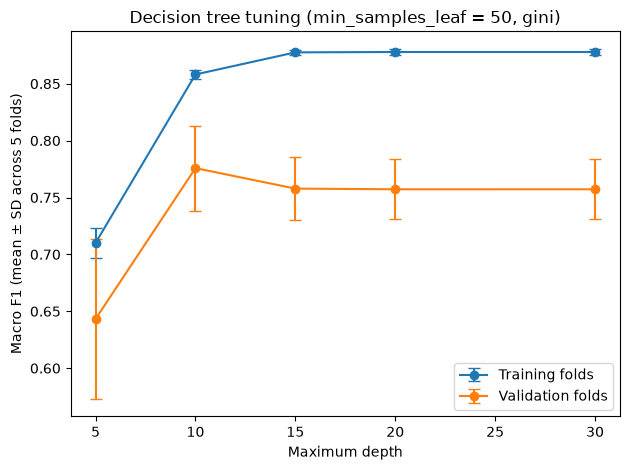

In [18]:
# Settings of the best tree, used to pick one line from the results
best_leaf = grid_tree.best_params_["min_samples_leaf"]
best_criterion = grid_tree.best_params_["criterion"]

# Keep the best leaf size and criterion, and drop max_depth=None (it can't go on a numeric axis)
tree_plot = tree_results[(tree_results["param_min_samples_leaf"] == best_leaf) &
                         (tree_results["param_criterion"] == best_criterion) &
                         (tree_results["param_max_depth"].notna())]

# Training vs validation macro F1 against depth: the gap shows overfitting
plt.errorbar(tree_plot["param_max_depth"], tree_plot["mean_train_f1"],
             yerr=tree_plot["std_train_f1"], marker="o", capsize=4, label="Training folds")
plt.errorbar(tree_plot["param_max_depth"], tree_plot["mean_test_f1"],
             yerr=tree_plot["std_test_f1"], marker="o", capsize=4, label="Validation folds")

plt.xlabel("Maximum depth")
plt.ylabel("Macro F1 (mean ± SD across 5 folds)")
plt.title(f"Decision tree tuning (min_samples_leaf = {best_leaf}, {best_criterion})")
plt.legend()
plt.tight_layout()
plt.show()


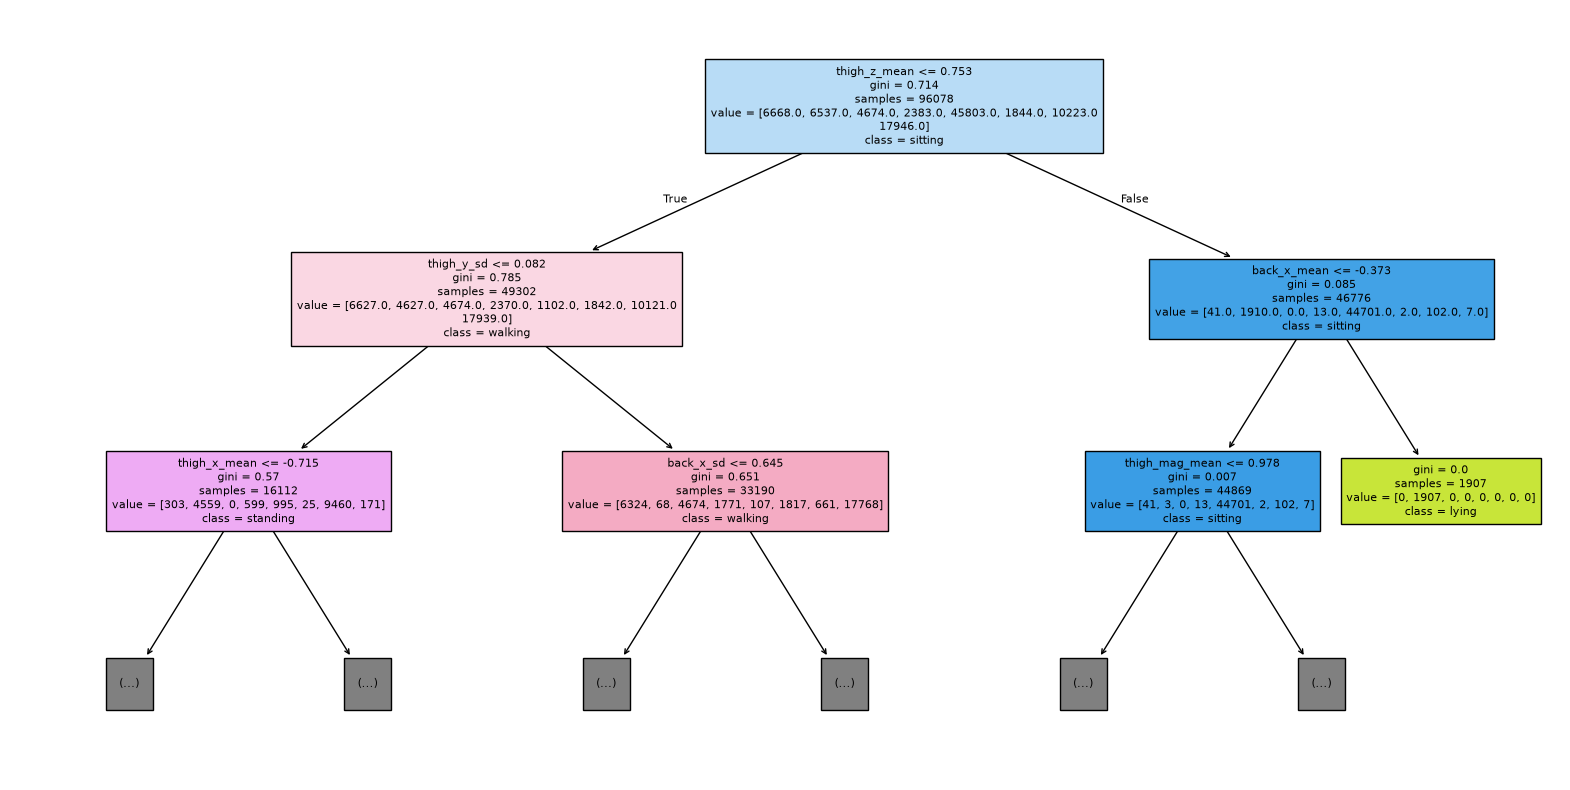

In [19]:
# Best Decision tree model (max_depth = 10, min_samples_leaf = 50, criterion = gini)
best_tree = grid_tree.best_estimator_

# Draw the top 2 levels of the best tree
plt.figure(figsize=(20, 10))
plot_tree(best_tree, feature_names=X.columns, class_names=best_tree.classes_,
          filled=True, max_depth=2, fontsize=8)
plt.show()

In [20]:
# Evaluate the tuned model with the same folds and metrics as other models
results_best_tree = cross_validate(best_tree, X, y, groups=groups, cv=cv,
                                   scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"})
pred_best_tree = cross_val_predict(best_tree, X, y, groups=groups, cv=cv)

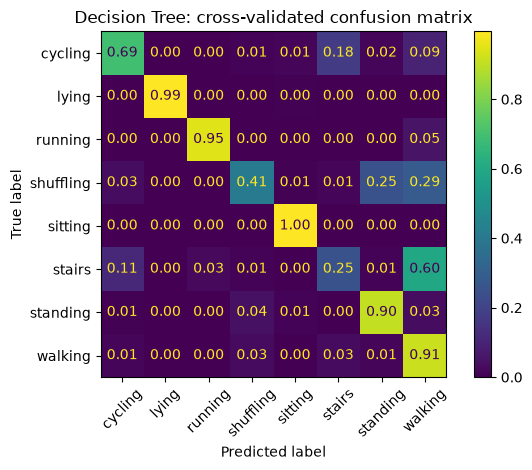

In [21]:
# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(y, pred_best_tree, normalize="true", values_format=".2f", xticks_rotation=45)
plt.title("Decision Tree: cross-validated confusion matrix")
plt.tight_layout()
plt.show()

In [22]:
results_tree_dict = results_dict("Decision Tree", results_best_tree) 
# Combine all models into one results table (mean ± SD across folds)
# One row per model
results_table = [results_dummy_dict, 
                 results_logreg_dict, 
                 results_knn_dict,
                results_tree_dict]
results_table = pd.DataFrame(results_table).set_index("Model")
results_table

,Macro F1,Balanced Accuracy,Training Time (s),Prediction Time
Model,,,,
Dummy (most frequent),0.081 ± 0.007,0.125 ± 0.000,0.07,0.10
Logistic Regression,0.809 ± 0.039,0.802 ± 0.036,4.18,0.14
"k-NN (k = 15, Manhattan)",0.808 ± 0.030,0.799 ± 0.047,0.18,12.12
Decision Tree,0.776 ± 0.037,0.775 ± 0.049,2.90,0.16


- Tuned max_depth (5 to 30, and no limit), min_samples_leaf (1 to 200) and criterion (gini, entropy). No scaler needed because trees split on thresholds.
- Best: gini, max_depth = 10, min_samples_leaf = 50. Macro F1 0.776 ± 0.037.
- Clear overfitting with no limits: training F1 1.000 vs validation 0.737. Underfitting at depth 5 (training 0.71, validation 0.64).
- With min_samples_leaf of 50 or more, depths of 15 and above give identical scores, because the leaf size stops the tree growing before the depth limit is reached.
- The top splits follow posture, then movement: thigh orientation (thigh_z_mean) first, back orientation (back_x_mean) to separate sitting from lying, and thigh movement variability (thigh_y_sd) to separate standing from walking.
- Weakest classes: stairs (0.25, mostly predicted as walking) and cycling (0.69, partly predicted as stairs). Lower overall than logistic regression and kNN. This is expected for a single tree and I will try a random forest next.

### Random Forest Model

In [23]:
# n_estimators kept small because of computation time & adding more would likely not make much difference
model_forest = RandomForestClassifier(n_estimators=200,n_jobs=-1, random_state=42) 

# Try settings: max_depth, min_samples_leaf
# grid was kept small because of computation time
param_grid_forest = {
    "max_depth" : [None, 10, 20],
    "min_samples_leaf": [1, 10, 50],
}

# Tune with same grouped 5-fold cross-validation as baselines.
# Use f1 to choose best settings
grid_forest = GridSearchCV(model_forest, param_grid_forest, cv=cv, 
                        scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"},
                        refit="f1",
                        return_train_score=True)

grid_forest.fit(X, y, groups=groups)

# Best settings and mean macro F1 across the 5 folds
print(grid_forest.best_params_)
print(grid_forest.best_score_)

{'max_depth': None, 'min_samples_leaf': 1}
0.8319686303853194


In [24]:
# Scores for every combination tried
forest_results = pd.DataFrame(grid_forest.cv_results_)
forest_results[["param_max_depth", "param_min_samples_leaf", "mean_train_f1", 
              "mean_test_f1", "std_test_f1", "mean_test_balanced_accuracy"]]

,param_max_depth,param_min_samples_leaf,mean_train_f1,mean_test_f1,std_test_f1,mean_test_balanced_accuracy
0,None,1,1.000000,0.831969,0.008678,0.835296
1,None,10,0.929716,0.821161,0.009813,0.821151
2,None,50,0.876061,0.785933,0.014227,0.784833
3,10,1,0.878163,0.785442,0.025728,0.782443
4,10,10,0.867792,0.781088,0.023111,0.778293
5,10,50,0.836993,0.760582,0.017085,0.764873
6,20,1,0.988412,0.827908,0.005630,0.829297
7,20,10,0.928718,0.818376,0.011745,0.818778
8,20,50,0.876575,0.786064,0.013739,0.784898


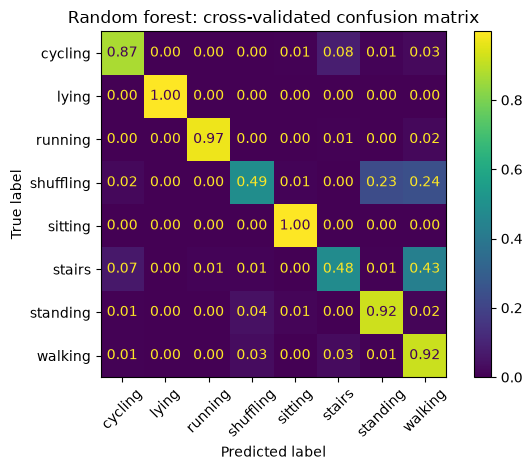

In [25]:
# Best random forest model (max_depth = None, min_samples_leaf = 1)
best_forest = grid_forest.best_estimator_

# Evaluate the tuned model with the same folds and metrics as other models
results_best_forest = cross_validate(best_forest, X, y, groups=groups, cv=cv,
                                    scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"})
pred_best_forest = cross_val_predict(best_forest, X, y, groups=groups, cv=cv)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(y, pred_best_forest, normalize="true", values_format=".2f", xticks_rotation=45)
plt.title("Random forest: cross-validated confusion matrix")
plt.tight_layout()
plt.show()

In [26]:
# Fold-by-fold macro F1: forest vs logistic regression on the same 5 folds.
# Comparing within each fold shows whether it is consistently better
print(results_best_forest["test_f1"])
print(results_logreg["test_f1"])

[0.84685474 0.82735971 0.82049286 0.83336912 0.83176672]
[0.82604555 0.74698895 0.78986482 0.86129377 0.8228837 ]


In [27]:
results_forest_dict = results_dict("Random Forest", results_best_forest) 
# Combine all models into one results table (mean ± SD across folds)
# One row per model
results_table = [results_dummy_dict, 
                 results_logreg_dict, 
                 results_knn_dict,
                 results_tree_dict,
                 results_forest_dict]
results_table = pd.DataFrame(results_table).set_index("Model")
results_table

,Macro F1,Balanced Accuracy,Training Time (s),Prediction Time
Model,,,,
Dummy (most frequent),0.081 ± 0.007,0.125 ± 0.000,0.07,0.10
Logistic Regression,0.809 ± 0.039,0.802 ± 0.036,4.18,0.14
"k-NN (k = 15, Manhattan)",0.808 ± 0.030,0.799 ± 0.047,0.18,12.12
Decision Tree,0.776 ± 0.037,0.775 ± 0.049,2.90,0.16
Random Forest,0.832 ± 0.009,0.835 ± 0.025,19.04,0.26


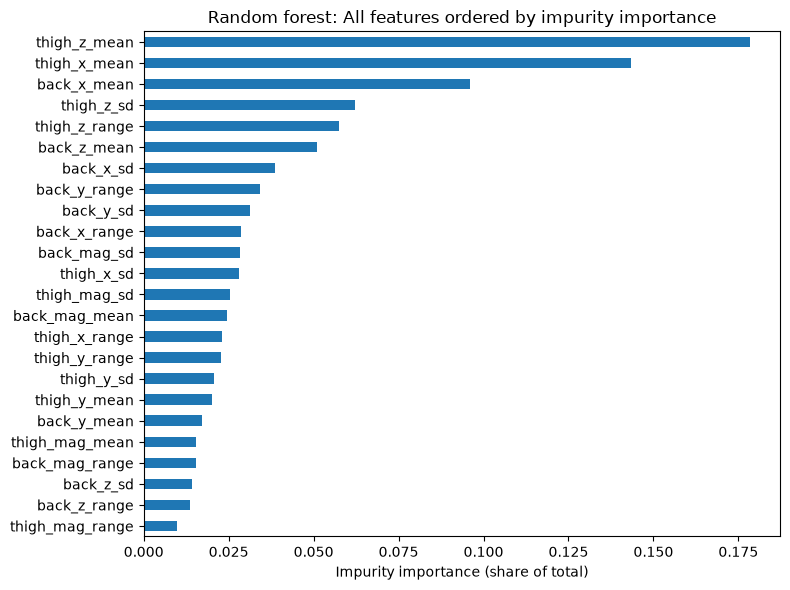

In [28]:
# Impurity importance: how much each feature improved the forest's splits, averaged over all 200 trees
# (calculated from the training data the forest was fitted on)
importance = pd.Series(best_forest.feature_importances_, index=X.columns).sort_values()

# Plot features in order of importance
importance.tail(24).plot(kind="barh", figsize=(8, 6))
plt.xlabel("Impurity importance (share of total)")
plt.title("Random forest: All features ordered by impurity importance")
plt.tight_layout()
plt.show()

- 200 trees (chose 200 because of computational power and adding more likey would not improve the result). Tuned max_depth (10, 20, no limit) and min_samples_leaf (1, 10, 50). Grid was kept small because each fit trains 200 trees, so computational power is high.
- Best: no depth limit, min_samples_leaf = 1. Macro F1 0.832 ± 0.009. Highest of all models so far :)
- Unlike the single tree, the forest does best with fully grown trees. Each tree overfits (training F1 1.000), but averaging 200 trees trained on different samples and features cancels most of this out. Limiting the trees made the forest worse (0.761 at depth 10, leaf 50).
- Depth 20 and no limit scored almost the same (0.828 vs 0.832)
- Much more stable across folds than any other model (SD 0.009, against 0.03 to 0.04).
- Fold-by-fold against logistic regression (same folds): the forest scored higher in 4 of 5 folds. Its lowest fold score (0.820) was well above logistic regression's (0.747, fold 2). Logistic regression did better only in fold 4, which contains S027 (over half of all running data). (possible reason is that a simpler linear model generalises better when an activity has few training examples)
- Confusion matrix: shuffling 0.49, stairs: 0.48 - better than other models (NEED TO PLOT TABLE)
- Training time: 19.04s per fold, the slowest so far. Prediction time: 0.26 s.
- Plotted a graph of feature importance and ... (interpret properly
- Did not use out-of-bag score: windows a tree doesn't sample still come from the same participants, so it would give an optimistic score.

### Gradient Boosting

In [32]:
# max_iter fixed at 300 rather than tuned, to limit computation time.
# 300 rounds should give the lowest learning rate (0.05) enough rounds to learn.
model_boost = HistGradientBoostingClassifier(max_iter = 300, early_stopping=False, random_state=42) 

# Try settings: learning_rate and max_leaf_nodes
# grid kept small because of computation time
param_grid_boost = {
    "learning_rate" : [0.05, 0.1, 0.2],
    "max_leaf_nodes": [15, 31, 63],
}

# Tune with same grouped 5-fold cross-validation as baselines.
# Use f1 to choose best settings
grid_boost = GridSearchCV(model_boost, param_grid_boost, cv=cv, 
                        scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"},
                        refit="f1",
                        return_train_score=True)

grid_boost.fit(X, y, groups=groups)

# Best settings and mean macro F1 across the 5 folds
print(grid_boost.best_params_)
print(grid_boost.best_score_)

{'learning_rate': 0.05, 'max_leaf_nodes': 15}
0.8117320878465959


In [48]:
# Scores for every combination tried
boost_results = pd.DataFrame(grid_boost.cv_results_)
boost_results[["param_learning_rate", "param_max_leaf_nodes", "mean_train_f1", 
              "mean_test_f1", "std_test_f1", "mean_test_balanced_accuracy"]]

,param_learning_rate,param_max_leaf_nodes,mean_train_f1,mean_test_f1,std_test_f1,mean_test_balanced_accuracy
0,0.05,15,0.975299,0.811732,0.023329,0.821478
1,0.05,31,0.999045,0.810981,0.024836,0.818102
2,0.05,63,1.000000,0.808398,0.026891,0.818355
3,0.10,15,0.799455,0.684816,0.078982,0.696879
4,0.10,31,0.822231,0.708827,0.145819,0.738087
5,0.10,63,0.936280,0.758629,0.100617,0.774054
6,0.20,15,0.699151,0.577748,0.093605,0.600495
7,0.20,31,0.598084,0.528202,0.072116,0.558541
8,0.20,63,0.539094,0.463214,0.208684,0.489248


In [47]:
# Second search: the best setting from the first search (0.05, 15 leaves) was at the edge of the grid, 
# so lower values and more rounds are tested.
model_boost2 = HistGradientBoostingClassifier(early_stopping=False, random_state=42) 

# Try lower settings for learning_rate and max_leaf_nodes
param_grid_boost2 = {
    "max_iter": [300, 600],
    "learning_rate" : [0.02, 0.05],
    "max_leaf_nodes": [5, 15]
}

# Tune with same grouped 5-fold cross-validation as baselines.
# Use f1 to choose best settings
grid_boost2 = GridSearchCV(model_boost2, param_grid_boost2, cv=cv, 
                         scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"},
                         refit="f1",
                         return_train_score=True)

grid_boost2.fit(X, y, groups=groups)

# Best settings and mean macro F1 across the 5 folds
print(grid_boost2.best_params_)
print(grid_boost2.best_score_)

{'learning_rate': 0.02, 'max_iter': 600, 'max_leaf_nodes': 15}
0.814053092677246


In [49]:
# Scores for every combination tried
boost_results2 = pd.DataFrame(grid_boost2.cv_results_)
boost_results2[["param_max_iter", "param_learning_rate","param_max_leaf_nodes", 
                "mean_train_f1", "mean_test_f1", "std_test_f1", "mean_test_balanced_accuracy"]]

,param_max_iter,param_learning_rate,param_max_leaf_nodes,mean_train_f1,mean_test_f1,std_test_f1,mean_test_balanced_accuracy
0,300,0.02,5,0.900774,0.797406,0.015654,0.809344
1,300,0.02,15,0.939788,0.809470,0.023611,0.819301
2,600,0.02,5,0.917443,0.805644,0.016693,0.816503
3,600,0.02,15,0.965748,0.814053,0.023173,0.822737
4,300,0.05,5,0.898243,0.765614,0.072663,0.787597
5,300,0.05,15,0.975299,0.811732,0.023329,0.821478
6,600,0.05,5,0.910529,0.761988,0.059929,0.771516
7,600,0.05,15,0.997317,0.810846,0.022317,0.820344


### Second boosting search
The best setting from the first search (learning_rate 0.05, max_leaf_nodes 15) was at the edge of the grid, so a second search tried a lower learning rate (0.02), more rounds (600) and smaller trees (5 leaves).

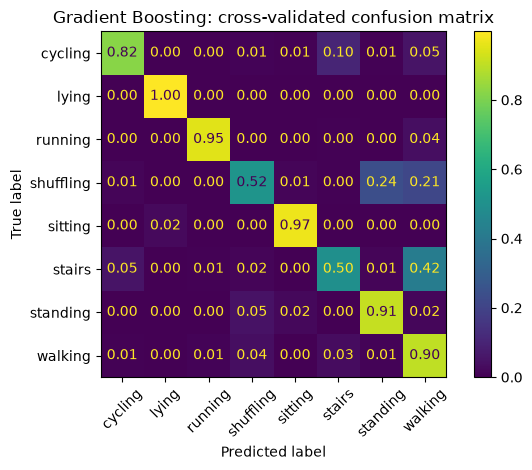

In [50]:
# Best random forest model (max_iter = 600, learning_rate = 0.02, max_leaf_nodes = 15)
best_boost = grid_boost2.best_estimator_

# Evaluate the tuned model with the same folds and metrics as other models
results_best_boost = cross_validate(best_boost, X, y, groups=groups, cv=cv,
                                    scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"})
pred_best_boost = cross_val_predict(best_boost, X, y, groups=groups, cv=cv)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(y, pred_best_boost, normalize="true", values_format=".2f", xticks_rotation=45)
plt.title("Gradient Boosting: cross-validated confusion matrix")
plt.tight_layout()
plt.show()

In [51]:
results_boost_dict = results_dict("Gradient Boosting", results_best_boost) 
# Combine all models into one results table (mean ± SD across folds)
# One row per model
results_table = [results_dummy_dict, 
                 results_logreg_dict, 
                 results_knn_dict,
                 results_tree_dict,
                 results_forest_dict,
                 results_boost_dict]
results_table = pd.DataFrame(results_table).set_index("Model")
results_table

,Macro F1,Balanced Accuracy,Training Time (s),Prediction Time
Model,,,,
Dummy (most frequent),0.081 ± 0.007,0.125 ± 0.000,0.07,0.10
Logistic Regression,0.809 ± 0.039,0.802 ± 0.036,4.18,0.14
"k-NN (k = 15, Manhattan)",0.808 ± 0.030,0.799 ± 0.047,0.18,12.12
Decision Tree,0.776 ± 0.037,0.775 ± 0.049,2.90,0.16
Random Forest,0.832 ± 0.009,0.835 ± 0.025,19.04,0.26
Gradient Boosting,0.814 ± 0.023,0.823 ± 0.022,26.99,1.57


- Used HistGradientBoostingClassifier (faster than GradientBoostingClassifier on large data)
- First search: learning_rate 0.05, 0.1, 0.2 × max_leaf_nodes 15, 31, 63, with 300 rounds. Best: 0.05 and 15 leaves (0.812 ± 0.023). Higher learning rates were unstable: at 0.2 and 63 leaves, macro F1 fell to 0.463 and training F1 also dropped (0.54), so the model failed to learn
- Second search: learning_rate 0.02, 0.05 × max_iter 300, 600 × max_leaf_nodes 5, 15. Best: 0.02, 600 rounds, 15 leaves. Macro F1 0.814 ± 0.023, a very slight gain (within the fold SD)
- 5 leaves was worse than 15, so very small trees were too simple
- Slowest model to train 

In [52]:
# Fold-by-fold macro F1: 

fold_results_table = pd.DataFrame({
    "Logistic Regression" : results_logreg["test_f1"],
    "kNN" : results_best_knn["test_f1"],
    "Decision Tree" : results_best_tree["test_f1"],
    "Random Forest" : results_best_forest["test_f1"],
    "Gradient Boosting" : results_best_boost["test_f1"]
}, index=["Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"]).round(3)

fold_results_table

,Logistic Regression,k-NN,Decision Tree,Random Forest,Gradient Boosting
Fold 1,0.826,0.828,0.796,0.847,0.841
Fold 2,0.747,0.759,0.779,0.827,0.828
Fold 3,0.790,0.789,0.732,0.820,0.805
Fold 4,0.861,0.824,0.833,0.833,0.774
Fold 5,0.823,0.841,0.739,0.832,0.823


In [56]:
# table of F1 for all activities & models
# Cross-validated predictions for each learned model
predictions = {
    "Logistic Regression": pred_logreg,
    "kNN": pred_best_knn,
    "Decision Tree": pred_best_tree,
    "Random Forest": pred_best_forest,
    "Gradient Boosting": pred_best_boost,
}

# F1 for each activity, for each model
activities = best_forest.classes_
per_class_f1 = pd.DataFrame({
    name: f1_score(y, pred, labels=activities, average=None)
    for name, pred in predictions.items()
}, index=activities).round(3)

per_class_f1


,Logistic Regression,kNN,Decision Tree,Random Forest,Gradient Boosting
cycling,0.907,0.909,0.771,0.904,0.882
lying,0.985,0.937,0.995,0.992,0.920
running,0.966,0.958,0.963,0.978,0.959
shuffling,0.438,0.482,0.441,0.505,0.504
sitting,0.995,0.985,0.995,0.996,0.983
stairs,0.448,0.465,0.230,0.459,0.447
standing,0.903,0.908,0.901,0.922,0.914
walking,0.909,0.905,0.878,0.910,0.897


In [41]:
# Precision, recall and F1 for each activity from the random forest's cross-validated predictions.
print(classification_report(y, pred_best_forest, digits=3))

              precision    recall  f1-score   support

     cycling      0.939     0.871     0.904      6668
       lying      0.986     0.998     0.992      6537
     running      0.986     0.971     0.978      4674
   shuffling      0.519     0.491     0.505      2383
     sitting      0.995     0.997     0.996     45803
      stairs      0.439     0.481     0.459      1844
    standing      0.924     0.921     0.922     10223
     walking      0.900     0.920     0.910     17946

    accuracy                          0.942     96078
   macro avg      0.836     0.831     0.833     96078
weighted avg      0.942     0.942     0.942     96078



### Model comparison
- Random forest has the highest macro F1 (0.832 ± 0.009) and is the most consistent across folds. It scored higher than logistic regression in 4 of 5 folds, and its lowest fold (0.820) was well above logistic regression's (0.747).
- Logistic regression was best in fold 4 (0.861), which contains S027 (over half of all running data). Gradient boosting was weakest in that fold (0.774).
- All learned models do well on sitting, lying, running, standing and walking (F1 about 0.90 or above, except the decision tree on cycling and boosting on lying).

### Error analysis
- Every model struggles with the shuffling and stairs activities. Shuffling F1 is 0.44 to 0.51 and stairs 0.45 to 0.47 (0.23 for the decision tree).
- Stairs is mostly confused with walking, in both directions: the forest finds 48% of stairs windows, but only 44% of its stairs predictions are correct, because many walking windows are labelled stairs. Shuffling is confused with both standing and walking.
- Because all models fail on the same classes, the limit is likely to be the features rather than the models. They are also the smallest classes.
- Accuracy for the random forest is 0.942 but macro F1 is 0.833. Sitting (45,803 windows, F1 0.996) dominates accuracy so macro F1 is better to use.

### Draft conclusion so far
- **Current best model:** random forest (200 trees, no depth limit, min_samples_leaf 1).
- **Evidence:** highest macro F1 (0.832 ± 0.009), most consistent across folds, best or joint best on most activities.
- **Limitations:** shuffling and stairs remain weak for every model; slower to train than the baselines; tuning scores are slightly optimistic because no nested CV was used.
- **Next steps:** PCA to check whether the hard classes overlap in feature space; feature importance for interpretability; a single final evaluation on the 4 test participants.